# Genotypes: what goes in comes back

A genotype is what an individual inherits and mutates. seachange stores each one in the run's database through a codec, a small object that turns a genotype into bytes and back. JSON values (lists and dicts) and numpy arrays work out of the box; any other type needs a codec of its own.

This notebook stores several genotypes, reads them back from the file, looks at the raw bytes, compares the stored sizes of JSON and numpy, and adds a codec for frozensets.

In [1]:
# standard library
import sqlite3
from pathlib import Path

In [2]:
# third-party
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray
from sqlalchemy.exc import StatementError

In [3]:
# local
from seachange import (
    EA,
    Archive,
    Individual,
    JsonCodec,
    NumpyCodec,
    Population,
    register_codec,
)

In [4]:
%matplotlib inline
plt.rcParams["figure.dpi"] = 72

SEED = 3
rng = np.random.default_rng(SEED)
DATA = Path("__data__")
DATABASE = DATA / "genotypes.db"
SIZES = [10, 100, 1_000, 10_000]

## A round trip through the database

`store_and_read` saves one individual per genotype in a fresh database (an `EA` with no operations stores its first population and stops), then reads them back with `Archive`. Each individual's fitness is its position, so they come back in order.

In [5]:
def store_and_read(genotypes: list[object]) -> list[object]:
    """Store each genotype in a fresh database and read them back in order.

    Returns
    -------
    list[object]
        The genotypes as read from the file.
    """
    individuals = []
    for position, genotype in enumerate(genotypes):
        individual: Individual[object] = Individual()
        individual.genotype = genotype
        individual.fitness = position
        individuals.append(individual)
    with EA(
        Population(individuals),
        [],
        num_steps=0,
        db_file_path=DATABASE,
        quiet=True,
    ):
        pass
    with Archive(DATABASE) as archive:
        stored = archive.hall_of_fame(n=len(genotypes), direction="min")
        return [individual.genotype for individual in stored]

In [6]:
weights = rng.standard_normal((2, 3)).astype(np.float32)
going_in: list[object] = [
    [0, 1, 1, 0],
    {"layers": [4, 8, 1], "activation": "tanh"},
    weights,
    np.array([True, False, True]),
    np.arange(5, dtype=np.int8),
]
coming_out = store_and_read(going_in)
for after in coming_out:
    kind = (
        f"{after.dtype} {after.shape}"
        if isinstance(after, np.ndarray)
        else type(after).__name__
    )
    print(f"{kind:<16} {after!r}".replace("\n", " "))

list             [0, 1, 1, 0]
dict             {'layers': [4, 8, 1], 'activation': 'tanh'}
float32 (2, 3)   array([[ 2.040919  , -2.555665  ,  0.41809884],        [-0.5677696 , -0.4526493 , -0.21559717]], dtype=float32)
bool (3,)        array([ True, False,  True])
int8 (5,)        array([0, 1, 2, 3, 4], dtype=int8)


In [7]:
assert coming_out[:2] == going_in[:2]
for before, after in zip(going_in[2:], coming_out[2:], strict=True):
    assert isinstance(after, np.ndarray)
    assert isinstance(before, np.ndarray)
    assert after.dtype == before.dtype
    assert np.array_equal(after, before)

A JSON genotype comes back as JSON: a tuple becomes a list, and a dict's number keys become strings. Use lists and string keys, or a numpy array, when the exact type matters.

In [8]:
print(store_and_read([(1, 2, 3), {1: "a"}]))

[[1, 2, 3], {'1': 'a'}]


## What is in the file

The genotype column holds the codec's name, a zero byte, and the codec's bytes. For numpy those bytes are a complete `.npy` file, so numpy can read a stored genotype without seachange.

In [9]:
store_and_read([[0, 1, 1, 0], weights])
with sqlite3.connect(DATABASE) as connection:
    rows = connection.execute(
        "SELECT genotype_ FROM individual ORDER BY fitness_"
    ).fetchall()
connection.close()
for (blob,) in rows:
    name, _, payload = blob.partition(b"\0")
    print(
        f"{name.decode():<6} {len(payload):>4} bytes, starts {payload[:12]!r}"
    )

json     12 bytes, starts b'[0, 1, 1, 0]'
numpy   152 bytes, starts b"\x93NUMPY\x01\x00v\x00{'"


In [10]:
assert rows[1][0].startswith(b"numpy\0\x93NUMPY")

## Stored size: JSON text against raw bytes

The same float32 weights, stored as a JSON list and as a numpy array. JSON spends about 20 characters per weight, numpy 4 bytes plus a 128-byte header. With 10,000 weights per individual and 100 individuals per generation, that is the difference between a database that grows by 20 MB a generation and one that grows by 4 MB.

In [11]:
json_bytes = []
numpy_bytes = []
for size in SIZES:
    vector = rng.standard_normal(size).astype(np.float32)
    json_bytes.append(len(JsonCodec().encode(vector.tolist())))
    numpy_bytes.append(len(NumpyCodec().encode(vector)))
    print(
        f"{size:>6} weights: json {json_bytes[-1]:>7} B,"
        f" numpy {numpy_bytes[-1]:>6} B"
    )

    10 weights: json     210 B, numpy    168 B
   100 weights: json    2059 B, numpy    528 B
  1000 weights: json   20611 B, numpy   4128 B
 10000 weights: json  206288 B, numpy  40128 B


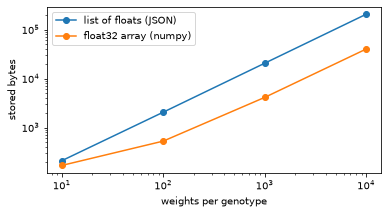

In [12]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.loglog(SIZES, json_bytes, marker="o", label="list of floats (JSON)")
ax.loglog(SIZES, numpy_bytes, marker="o", label="float32 array (numpy)")
ax.set_xlabel("weights per genotype")
ax.set_ylabel("stored bytes")
ax.legend()
plt.show()

In [13]:
assert all(n < j for n, j in zip(numpy_bytes, json_bytes, strict=True))

## A genotype is set once

Assigning an array to `genotype` makes it read-only, so a child can never change its parent's weights by accident. Make the child's genotype a new array instead.

In [14]:
parent: Individual[NDArray[np.float32]] = Individual()
parent.genotype = np.zeros(3, dtype=np.float32)
try:
    parent.genotype += 1
except ValueError as error:
    print("in place:", error)
child: Individual[NDArray[np.float32]] = Individual()
child.genotype = parent.genotype + 1
print("parent:", parent.genotype, " child:", child.genotype)
assert not parent.genotype.any()

in place: output array is read-only
parent: [0. 0. 0.]  child: [1. 1. 1.]


## Your own genotype type

A codec has a `name` and three methods: `handles` says whether it stores a value, `encode` turns it into bytes, `decode` turns bytes back. Registered codecs are asked first. This one stores a frozenset of strings as a sorted JSON list. Without it, a frozenset cannot be stored at all: saving it raises an error that names the type.

In [15]:
# Behaviour, not a record: a codec holds no data
class FrozensetCodec:
    """Store a frozenset of strings as a sorted JSON list."""

    name = "frozenset"

    @staticmethod
    def handles(genotype: object) -> bool:
        """Return whether ``genotype`` is a frozenset.

        Returns
        -------
        bool
            True for a frozenset.
        """
        return isinstance(genotype, frozenset)

    @staticmethod
    def encode(genotype: object) -> bytes:
        """Return the sorted members as JSON text.

        Returns
        -------
        bytes
            The JSON text.
        """
        assert isinstance(genotype, frozenset)
        return JsonCodec().encode(sorted(genotype))

    @staticmethod
    def decode(data: bytes) -> frozenset[str]:
        """Return the frozenset stored in ``data``.

        Returns
        -------
        frozenset[str]
            The genotype.
        """
        return frozenset(str(member) for member in JsonCodec.decode(data))

In [16]:
try:
    store_and_read([frozenset({"leg", "arm"})])
except StatementError as error:
    print("before registering:", error.orig)

register_codec(FrozensetCodec())
print("after registering: ", store_and_read([frozenset({"leg", "arm"})]))

before registering: JsonCodec stores lists and dicts, not <class 'frozenset'>
after registering:  [frozenset({'arm', 'leg'})]


In [17]:
assert store_and_read([frozenset({"leg"})]) == [frozenset({"leg"})]

## Conclusions

Run on 2026-10-23 with `SEED = 3`.

- Lists, dicts and numpy arrays of float32, bool and int8 come back from the database equal to what went in, arrays with their dtype and shape.
- A tuple comes back as a list and the number key of a dict as a string (`(1, 2, 3)` as `[1, 2, 3]`, `{1: "a"}` as `{"1": "a"}`). This is the JSON aliases entry in PLAN.md Known problems, which waits on a decision.
- numpy stores float32 weights in 4 bytes each plus a 128-byte header; JSON takes about 20.6 bytes each. For 10,000 weights that is 40,128 B against 206,288 B, 5.1 times smaller.
- An assigned array is read-only, and a frozenset can be stored only once its codec is registered; without it, saving raises an error that names the type.